## This demonstrates the Vanishing gradient problem in deep learning by building a deep neural network twice: first using the sigmoid activation function, and then using ReLU

In [22]:
import matplotlib.pyplot as plt # Creates plots and visualizations
import numpy as np # For Numerical python
import pandas as pd # For Tabular data
import tensorflow as tf # Build and train Neural networks
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense  # Creates a fully connected neural network layer
from keras.models import Sequential # Builds a model by stacking layers in order

# Creating the dataset

In [23]:
# 250 observation
# noise = 0.05 --> Adds a small noise to the data
# X --> the input features, containing two numbers per observations
# y --> the target labels, either 0 or 1
X,y = make_moons(n_samples=250, noise=0.05, random_state=42)

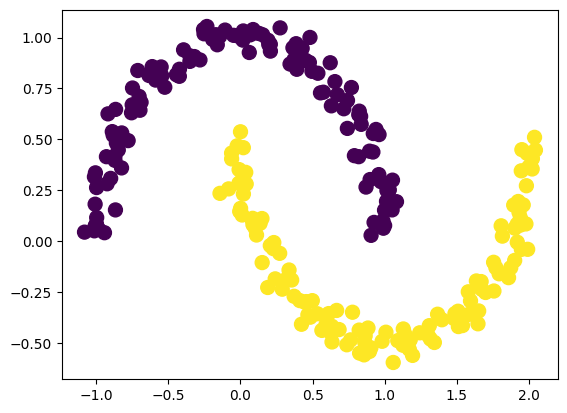

In [24]:
plt.scatter(X[:,0],X[:,1], c=y, s=100)
plt.show()

# Building the first neural network

In [25]:
# Sequential --> It creates an empty neural-network model to which you can add layers one after another. Think of it as an initially empty pipeline:
# Input --> L1 --> L2 --> L3 --> ... --> Output
model = Sequential()

# 10 hidden layers

# Dense --> A Dense layer is a fully connected layer. Each of its 10  neurons recieves input from every neuron in the previous layer.
# My input has two features, so the first hidden layer recieves two input values and produces 10 outputs

# Z= W.X + b
# Z --> Values calculated before activation, W --> Weights, X --> Input Values, b --> biases
# The activation function is then applied: A = sigmoid(Z)

# These are 10 hidden layers. Input Features: 2, Output Layer: 1 neuron with Sigmoid Activation

# model.add(...) --> Adds a layer to the model
# Dense(...) --> Creates a fully connected layer
# 10: Specifies that the layer contains 10 neurons
# sigmoid --> applies the sigmoid activation function to the neurons's outputs
# input_dim=2 --> specifies that each input observation contains two features
model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
model.add(Dense(10,activation='sigmoid'))
# The output layer. This adds a single output neuron. Since this is a classification problem, the sigmoid output represents the estimated probability of class 1.
model.add(Dense(1, activation='sigmoid'))

# What happens inside the first layer: Every neuron recieves both input features, multiplies them by its own weights, add its bias, and applies the sigmoid function. The same process happens in all 10 neurons, with different weights and biases

In [26]:
# This configures the training process
# Loss - BCE: measures how well the predicted probabilities match the true binary labels
# Optimizer --> Adam: uses gardient information to update the weights and biases
# Metric: Accuracy: reports the proportion of predictions classified correctly during training
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [27]:
# This returns a list containing the weight matrices and bias vectors for all layers.
# For example, the first 2 entries correspond to the first layer: model.get_weights()[0] --> its weight matrix, model.get_weights()[1] --> its bias vector
# For a Dense layer, the first element of that list is its weight matrix. Since I haven't trained the model yet, these are the initial weights
model.get_weights()

[array([[-0.17712432, -0.2780448 ,  0.22795749, -0.07723612, -0.6631611 ,
         -0.1809017 ,  0.6398589 ,  0.18329549,  0.35905832,  0.04258972],
        [-0.67290276, -0.20669019,  0.5191204 ,  0.6779447 , -0.52747357,
          0.03243166, -0.12401474,  0.09638733, -0.58281875,  0.6463652 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.04071856,  0.23472416, -0.5372812 , -0.49667016,  0.17021984,
          0.18329889, -0.4475034 , -0.4075479 ,  0.31071573, -0.18411887],
        [ 0.16346782, -0.43326533, -0.24334398, -0.029908  , -0.03854805,
         -0.4275233 ,  0.02780604, -0.06612611,  0.3231457 ,  0.49547637],
        [ 0.24599278, -0.09520763, -0.3539896 , -0.0564031 , -0.28593093,
          0.2941633 ,  0.23134732, -0.01592761, -0.09234974, -0.3254956 ],
        [ 0.32153022, -0.11789128, -0.19438028, -0.5191641 ,  0.37004036,
          0.0779627 , -0.521906  , -0.22073123,  0.2546724 , -0.15233368],
        [ 0.45080

In [28]:
# These are the initial weights so I can compare them with the weights after training. These are the weights of the first layer only. Keras initializes the weights automatically when the model is built. These are the initial values, not the values learned from the dataset. Biases are initialized too.
model.get_weights()[0]

array([[-0.17712432, -0.2780448 ,  0.22795749, -0.07723612, -0.6631611 ,
        -0.1809017 ,  0.6398589 ,  0.18329549,  0.35905832,  0.04258972],
       [-0.67290276, -0.20669019,  0.5191204 ,  0.6779447 , -0.52747357,
         0.03243166, -0.12401474,  0.09638733, -0.58281875,  0.6463652 ]],
      dtype=float32)

In [29]:
# I am saving these initial weights for the first layer because I want to compare them before and after training
old_weights_layer_one = model.get_weights()[0]

In [30]:
old_weights_layer_one

array([[-0.17712432, -0.2780448 ,  0.22795749, -0.07723612, -0.6631611 ,
        -0.1809017 ,  0.6398589 ,  0.18329549,  0.35905832,  0.04258972],
       [-0.67290276, -0.20669019,  0.5191204 ,  0.6779447 , -0.52747357,
         0.03243166, -0.12401474,  0.09638733, -0.58281875,  0.6463652 ]],
      dtype=float32)

In [31]:
# Training set: 200 observations
# Test Set: 50 observations

# The training set is used to learn the weights. The test set is intended to evaluate how well the model performs on the unseen data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

## Training the Sigmoid model. This is where the network starts learning

In [32]:
# This tells keras to train the model for 100 epochs

# During training, the following process repeats:
# 1 --> Forward propagation (the network predicts the class for each input)
# 2 --> Calculate loss (BCE measures prediction error)
# 3 --> backpropagation (Calculate gradients of the loss with respect to the weights)
# 4 --> Adam updates weights
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4900 - loss: 0.7526
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.7382 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.7283 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4900 - loss: 0.7178 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.7109 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.7056 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.7014 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.6991 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.6967 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.6950 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss: 0.6939 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4900 - loss

### Comparing weighs before and after training

In [33]:
new_weights_layer_one = model.get_weights()[0]

In [34]:
old_weights_layer_one

array([[-0.17712432, -0.2780448 ,  0.22795749, -0.07723612, -0.6631611 ,
        -0.1809017 ,  0.6398589 ,  0.18329549,  0.35905832,  0.04258972],
       [-0.67290276, -0.20669019,  0.5191204 ,  0.6779447 , -0.52747357,
         0.03243166, -0.12401474,  0.09638733, -0.58281875,  0.6463652 ]],
      dtype=float32)

In [35]:
new_weights_layer_one

array([[-0.4060188 , -0.4147452 ,  0.3363749 , -0.34573507, -0.64284116,
        -0.14256868,  0.73378825,  0.07315152,  0.31207973, -0.08729921],
       [-0.48327097, -0.09156761,  0.4325799 ,  0.89718664, -0.5453129 ,
        -0.00240486, -0.21588945,  0.18399076, -0.5454299 ,  0.7447299 ]],
      dtype=float32)

In [36]:
# Checking Adam's learning rate. The learning rate controls the size of the optimizer updates.
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [37]:
gradient = (old_weights_layer_one - new_weights_layer_one)/ 0.001

In [38]:
percent_change = abs(100*(old_weights_layer_one - new_weights_layer_one)/ old_weights_layer_one)

In [39]:
gradient

array([[ 228.89445 ,  136.70041 , -108.41742 ,  268.49893 ,  -20.319937,
         -38.333027,  -93.929344,  110.14396 ,   46.978592,  129.88893 ],
       [-189.63177 , -115.122574,   86.54049 , -219.24191 ,   17.839312,
          34.836517,   91.87472 ,  -87.60343 ,  -37.38886 ,  -98.36465 ]],
      dtype=float32)

In [40]:
percent_change

array([[129.22813  ,  49.16489  ,  47.56037  , 347.63394  ,   3.064103 ,
         21.189978 ,  14.679697 ,  60.09093  ,  13.083834 , 304.97717  ],
       [ 28.181158 ,  55.69813  ,  16.6706   ,  32.339203 ,   3.3820298,
        107.41515  ,  74.08371  ,  90.88688  ,   6.4151783,  15.2181225]],
      dtype=float32)

In [41]:
old_weights_layer_one

array([[-0.17712432, -0.2780448 ,  0.22795749, -0.07723612, -0.6631611 ,
        -0.1809017 ,  0.6398589 ,  0.18329549,  0.35905832,  0.04258972],
       [-0.67290276, -0.20669019,  0.5191204 ,  0.6779447 , -0.52747357,
         0.03243166, -0.12401474,  0.09638733, -0.58281875,  0.6463652 ]],
      dtype=float32)

In [42]:
new_weights_layer_one

array([[-0.4060188 , -0.4147452 ,  0.3363749 , -0.34573507, -0.64284116,
        -0.14256868,  0.73378825,  0.07315152,  0.31207973, -0.08729921],
       [-0.48327097, -0.09156761,  0.4325799 ,  0.89718664, -0.5453129 ,
        -0.00240486, -0.21588945,  0.18399076, -0.5454299 ,  0.7447299 ]],
      dtype=float32)

In [43]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [44]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [45]:
old_weights = model.get_weights()[0]

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [47]:
model.fit(X_train, y_train, epochs = 100)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4750 - loss: 0.6924
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7850 - loss: 0.6901 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7850 - loss: 0.6870 
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7750 - loss: 0.6824 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7700 - loss: 0.6755 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7800 - loss: 0.6665 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7800 - loss: 0.6532 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7950 - loss: 0.6342 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.6085 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8150 - loss: 0.5738 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8150 - loss: 0.5325 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8200 - loss

In [48]:
new_weights = model.get_weights()[0]

In [49]:
model.optimizer.get_config()["learning_rate"]

0.0010000000474974513

In [50]:
gradient = (old_weights - new_weights)/ 0.001
percent_change = abs(100*(old_weights - new_weights)/ old_weights)

In [51]:
gradient

array([[ -41.527508 , -164.97462  ,  -87.055916 , -148.64153  ,
         -92.003815 ,  -77.98211  ,  223.81287  , -138.92715  ,
         -29.115616 ,   -6.339192 ],
       [ 178.23033  ,  130.80147  , -149.00192  ,   -6.3793955,
        -134.9715   , -117.480034 ,  -42.501446 ,  110.30763  ,
        -298.71826  ,  116.91182  ]], dtype=float32)

In [52]:
percent_change

array([[  7.1191287, 253.09     ,  31.992363 ,  30.868101 ,  14.953652 ,
         28.74432  ,  80.36171  ,  34.49049  ,   4.678883 ,   1.2393405],
       [337.08902  ,  49.283607 ,  72.60412  ,   2.2254791,  19.941896 ,
         23.196983 ,  10.288742 ,  26.837902 , 106.90547  ,  16.572817 ]],
      dtype=float32)

In [53]:
old_weights

array([[ 0.58332294, -0.06518418,  0.2721147 ,  0.48153764, -0.6152599 ,
        -0.27129573, -0.27850688,  0.40279847,  0.6222771 ,  0.5114972 ],
       [-0.05287337, -0.26540563,  0.20522517,  0.28665268,  0.6768238 ,
         0.50644535,  0.41308695, -0.41101438, -0.27942282, -0.7054433 ]],
      dtype=float32)

In [54]:
new_weights

array([[ 0.62485045,  0.09979045,  0.35917062,  0.63017917, -0.52325606,
        -0.19331361, -0.50231975,  0.54172564,  0.6513927 ,  0.5178364 ],
       [-0.23110372, -0.3962071 ,  0.3542271 ,  0.29303208,  0.8117953 ,
         0.6239254 ,  0.4555884 , -0.521322  ,  0.01929545, -0.82235515]],
      dtype=float32)